In [1]:
using LinearAlgebra
using Plots
using Printf
using LaTeXStrings

using Distributed

BLAS.set_num_threads(1)
addprocs(8, enable_threaded_blas=false);

In [2]:
gr();
# pyplot();
# plotlyjs();

In [3]:
@everywhere push!(LOAD_PATH, pwd())
@everywhere using Revise

In [4]:
using RMProblems  # Load on a single node first in case recompilation is needed
using RMSolver    # Load on a single node first in case recompilation is needed
@everywhere workers() using RMProblems
@everywhere workers() using RMSolver

┌ Info: Precompiling RMSolver [top-level]
└ @ Base loading.jl:1278


In [5]:
N_full = 300
N = 3

σabs = 0.95
θ = pi / 6
u = 0.3

σ = θ == 0.0 ? σabs : σabs * exp(im * θ)

τ = 0.5
T = repeat(sqrt.([0.7; 0.5; 0.3]), div(N, 3))

problem_full = example_problems[5](N=N_full, σ=σ, u=u)
problem = example_problems[5](N=N, σ=σ, u=u)
problem.M

3×3 Bidiagonal{Complex{Float64},Array{Complex{Float64},1}}:
 -0.5+0.866025im   0.3+0.0im           ⋅    
      ⋅           -0.5-0.866025im  0.3+0.0im
      ⋅                ⋅           1.0-6.10623e-16im

In [6]:
using RMUtils

Mevs = unique(eigvals(problem.M))

Jr = (1 / sqrt(N_full)) * rand([-1.0; 1.0], (N_full, N_full))
Jr = partially_hermitize(Jr, τ)
LJrR = problem_full.L * Jr * problem_full.R
Ar = problem_full.M + LJrR

Arevs = eigvals(Ar)
Jrevs = eigvals(Jr);

Jc = (1 / sqrt(2N_full)) * (randn(N_full, N_full) + im * randn(N_full, N_full))
Jc = partially_hermitize(Jc, τ)
LJcR = problem_full.L * Jc * problem_full.R
Ac = problem_full.M + LJcR

Acevs = eigvals(Ac)
Jcevs = eigvals(Jc);

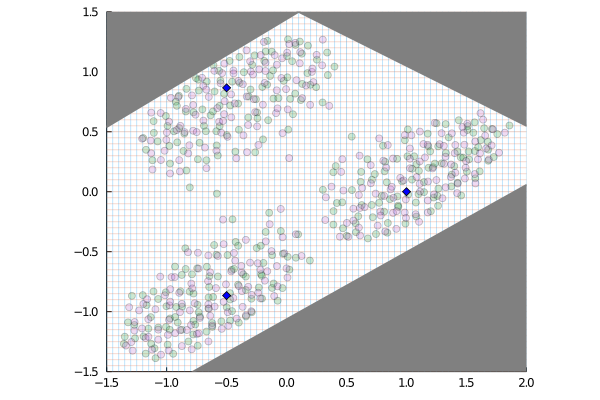

In [7]:
xs = -1.5:0.05:2.0
ys = -1.5:0.05:1.5

p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
scatter!(p, real(Arevs), imag(Arevs), alpha=0.25, aspect_ratio=:equal, label="")
scatter!(p, real(Acevs), imag(Acevs), alpha=0.25, aspect_ratio=:equal, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

function plot_mask!(p, bounds, ylims)
    for b in bounds
        if b.second === :L
            fr = ylims[1]
        elseif b.second === :U
            fr = ylims[end]
        else
            fr = nothing
        end
        plot!(p, b.first, lw=2, color=:gray, fillrange=fr, label="")
    end
    return p
end

bounds = Dict(
    (x ->  (2.8 / 5.0) * (x - 1.9)) => :L,
    (x -> -(2.5 / 5.0) * (x - 3.1)) => :U,
    (x ->  (3.0 / 5.0) * (x + 2.4)) => :U,
)
plot_mask!(p, bounds, ys)

In [8]:
rbase = 2.0
start = 7
stop = -5

solve_gsq, solve_k = rm_solvers(
    problem=problem, rbase=rbase, start=start, stop=stop
);

In [9]:
z = -0.9 + 0.3im

solution = solve_gsq(T, z, debug=true);
# solution = solve_k(T, z, debug=true);

  z = -0.900 + i 0.300
-------------------------------------------------------
   γ^2        δ^2               q                k
-------------------------------------------------------
 1.28e+02   1.28e+02  -3.16e-03 + i-3.43e-03   7.71e-03
 6.35e+01   6.40e+01  -6.18e-03 + i-6.75e-03   1.52e-02
 3.15e+01   3.20e+01  -1.19e-02 + i-1.30e-02   2.97e-02
 1.55e+01   1.60e+01  -2.20e-02 + i-2.44e-02   5.69e-02
 7.56e+00   8.00e+00  -3.89e-02 + i-4.33e-02   1.05e-01
 3.60e+00   4.00e+00  -6.52e-02 + i-7.00e-02   1.86e-01
 1.64e+00   2.00e+00  -1.05e-01 + i-9.85e-02   3.16e-01
 6.99e-01   1.00e+00  -1.66e-01 + i-1.11e-01   5.26e-01
 2.52e-01   5.00e-01  -2.57e-01 + i-6.59e-02   8.97e-01
-1.16e-01   2.50e-01  -3.57e-01 + i 2.55e-01   1.68e+00
-------------------------------------------------------
Results of univariate zero finding:

* Converged to: 0.4384832935570573
* Algorithm: Roots.FalsePosition{10}()
* iterations: 9
* function evaluations: 11
* stopped as |f(x_n)| ≤ max(δ, max(1,|x|)⋅ϵ)

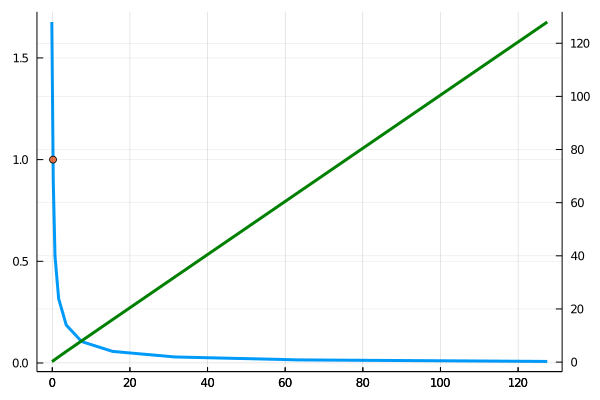

In [10]:
γsqs = [s.γsq for s in solution.trace]
δsqs = [s.δsq for s in solution.trace]
ks = [s.k for s in solution.trace]
plot(γsqs, ks, lw=3, label="")
scatter!([solution.γsq], [solution.k], label="")
plot!(
    twinx(),
    γsqs,
    δsqs,
    lw=3,
    color=:green,
    label="",
)

In [11]:
@everywhere solve_gsq, solve_k = rm_solvers(
    problem=$problem, rbase=$rbase, start=$start, stop=$stop,
)
@everywhere gsq = z -> solve_gsq($T, z)
@everywhere k = z -> solve_k($T, z)

function inbounds(x, y, bounds)
    for b in bounds
        if ((b.second === :L) && (y < b.first(x)))
            return false
        end
        if ((b.second === :U) && (y > b.first(x)))
            return false
        end
    end
    return true
end

zs = [inbounds(x, y, bounds) ? complex(x, y) : complex(NaN, NaN) for y in ys, x in xs];

In [12]:
solutions = pmap(k, zs);

In [13]:
qs = similar(zs)
gsqs = similar(zs, Float64)
ks = similar(zs, Float64)

function nanclamp(x::Real, lo, hi)
    if (x < lo) || (hi < x)
        return NaN
    end
    return x
end

function nanclamp(x::Complex, relo, rehi, imlo, imhi)
    return complex(nanclamp(real(x), relo, rehi), nanclamp(imag(x), imlo, imhi))
end

trunc = 2.0
for j in 1:length(xs)
    for i in 1:length(ys)
        s = solutions[i, j]
        gsqs[i, j] = s.γsq
        qs[i, j] = nanclamp(s.q, -trunc, trunc, -trunc, trunc)
        ks[i, j] = nanclamp(s.k, 0.0, trunc)
    end
end

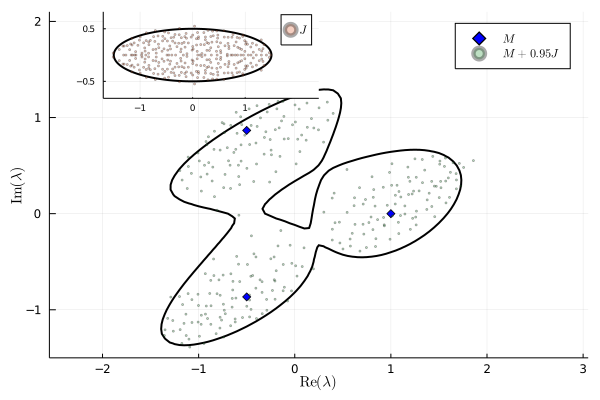

In [14]:
p = contour(
    xs,
    ys,
#     gsqs,
#     levels=[0.0],
    ks,
    levels=[1.0],
    linewidth=2,
    color=:black,
    colorbar_entry=false,
    aspect_ratio=:equal,
    #size=(270, 200),
    ylims=(ys[1], ys[end] + 0.6),
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)
scatter!(
    p,
    real(Mevs),
    imag(Mevs),
    markershape=:diamond,
    markercolor=:blue,
    aspect_ratio=:equal,
    label=L"M",
)

plot!(
    p,
    t -> (1 + τ) * cos(t),
    t -> (1 - τ) * sin(t),
    0,
    2pi,
    linewidth=2,
    color=:black,
    aspect_ratio=:equal,
    label="",
    xlims=(-1.7, 2.4),
    xticks=[-1.0; 0.0; 1.0],
    yticks=[-0.5; 0.5],
    tickfontsize=6,
    inset_subplots=(1, bbox(0.1, 0.0, 0.4, 0.25)),
    subplot=2,
)

scatter!(
    p,
    real(Arevs),
    imag(Arevs),
    # real(Acevs),
    # imag(Acevs),
    markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    label=L"M + 0.95 J",
    subplot=1,
)

scatter!(
    p,
    real(Jrevs),
    imag(Jrevs),
    # real(Jcevs),
    # imag(Jcevs),
    markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    label=L"J",
    subplot=2,
)

p

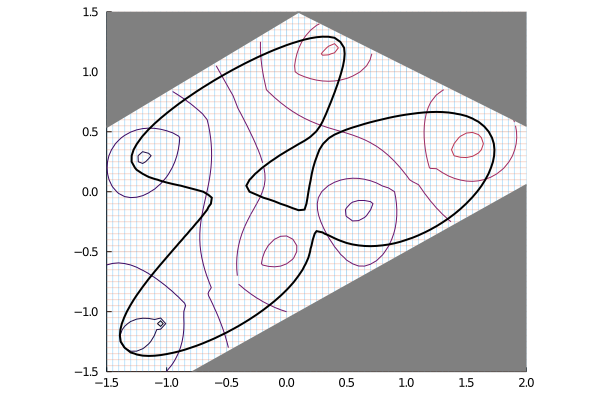

In [15]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, real(qs), aspect_ratio=:equal, colorbar=false)
# contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)

plot_mask!(p, bounds, ys)

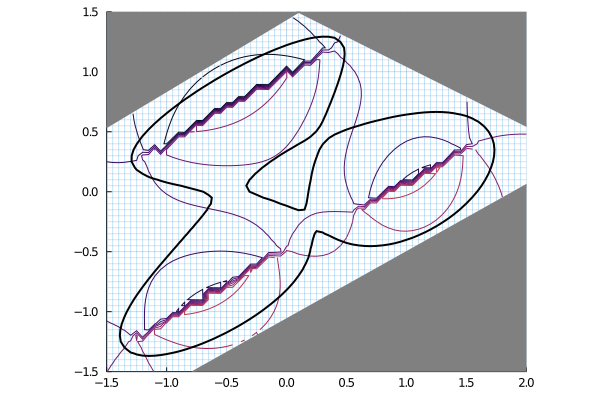

In [16]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, imag(qs), aspect_ratio=:equal, colorbar=false)
# contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)

plot_mask!(p, bounds, ys)

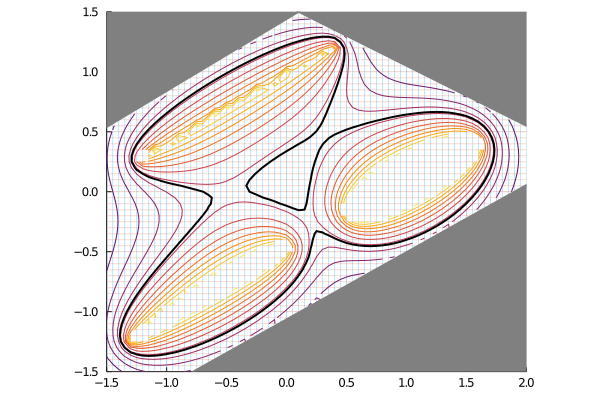

In [17]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
# contour!(p, xs, ys, gsqs, aspect_ratio=:equal, colorbar=false)
# contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
contour!(p, xs, ys, ks, aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)

plot_mask!(p, bounds, ys)

In [18]:
# Jacobian check
ws = RMSolver.RMWorkspace(problem)
RMSolver.G0i!(ws, z)
γsq = rbase ^ start
q = RMSolver.qstart(ws, T, γsq)
qv = [real(q); imag(q)];

In [19]:
# Analytical
Fv, Jv = zeros(2), zeros(2, 2)
RMSolver.qresidue!(Fv, Jv, ws, T, γsq, qv, Val(false))
Jv

2×2 Array{Float64,2}:
 -1.00381     -1.09475e-5
  1.09475e-5  -0.9962

In [20]:
# Numerical
δq = 0.001 * abs(q)
Fvδq = similar(Jv)
RMSolver.qresidue!((@view Fvδq[:, 1]), nothing, ws, T, γsq, qv .+ [δq, 0.0], Val(false))
RMSolver.qresidue!((@view Fvδq[:, 2]), nothing, ws, T, γsq, qv .+ [0.0, δq], Val(false))
(Fvδq .- Fv) / δq

2×2 Array{Float64,2}:
 -1.00381     -1.09474e-5
  1.09475e-5  -0.9962